In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [2]:
df = pd.read_csv(
    "../data/ecommerce_sales_cleaned.csv",
    parse_dates=["order_date"]
)

df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [3]:
df["order_year"] = df["order_date"].dt.year

df["order_month"] = df["order_date"].dt.month

df["order_day"] = df["order_date"].dt.day

df["day_of_week"] = df["order_date"].dt.dayofweek

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [4]:
X = df[
    [
        "quantity",
        "unit_price",
        "discount",
        "product_category",
        "region",
        "payment_method",
        "order_year",
        "order_month",
        "order_day",
        "day_of_week",
        "is_weekend"
    ]
]

y = df["revenue"]

In [5]:
categorical_features = [
    "product_category",
    "region",
    "payment_method"
]

numerical_features = [
    "quantity",
    "unit_price",
    "discount",
    "order_year",
    "order_month",
    "order_day",
    "day_of_week",
    "is_weekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4000, 11)
Testing Data: (1000, 11)


In [7]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

In [8]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [9]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        lr_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

comparison = pd.DataFrame(results)

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,219.647350,296.476505,0.869542
1,Random Forest,20.477568,30.775505,0.998594


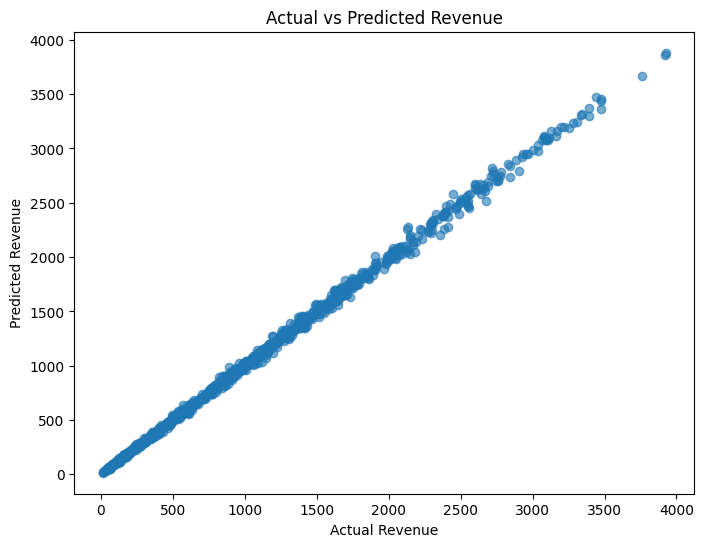

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6
)

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")

plt.title("Actual vs Predicted Revenue")

plt.show()

In [11]:
joblib.dump(
    rf_model,
    "../reports/revenue_prediction_model.pkl"
)

comparison.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model saved successfully!")

Model saved successfully!
